# Glass catalogues: glass maps, partial dispersion and an apochromatic doublet

`pyoptics.glasses` holds the catalogues of six glass makers, SCHOTT,
OHARA, HOYA, CDGM, SUMITA and HIKARI, about 1600 glasses, each with
the vendor's dispersion formula (taken from the refractiveindex.info
database, which took them from the vendors' Zemax catalogues). A `Glass`
is a function $n(\lambda)$ and serves directly as the material of a
`raytrace.Surface`.

This notebook

1. draws the glass map ($n_d$ over $V_d$) of all six catalogues,
2. compares the Abbe model glass $(n_d, V_d)$ used by the optimizer of
   notebook 58 with the real dispersion,
3. shows the partial dispersion diagram with the normal line and the
   glasses that leave it,
4. searches the catalogue for crown/flint pairs with a small secondary
   spectrum, the price being stronger lens powers, and optimizes a cemented
   doublet of the best pair against an ordinary N-BK7/N-F2 achromat,
5. turns the model glasses of an optimized doublet into real glasses
   from all catalogues (`DampedLeastSquares.snap_glasses()`) and corrects
   again.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import glasses as gl
from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics.materials import abbe_dispersion

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()
VENDOR_COLORS = {"SCHOTT": "#2a78d6", "OHARA": "#eb6834", "HOYA": "#1baf7a", "CDGM": "#eda100",
                 "SUMITA": "#e87ba4", "HIKARI": "#7b5cc4"}
everything = gl.catalog("all")
print(f"{len(everything)} glasses:", {v: len(gl.load(v)) for v in gl.VENDORS})
bk7 = gl.get("N-BK7")
print(bk7, {line: round(float(bk7.n(line)), 5) for line in ("g", "F", "e", "d", "C")})

1609 glasses: {'schott': 156, 'ohara': 410, 'hoya': 190, 'cdgm': 314, 'sumita': 176, 'hikari': 363}
Glass('N-BK7', SCHOTT, n_d=1.51680, V_d=64.17) {'g': 1.52669, 'F': 1.52238, 'e': 1.51872, 'd': 1.5168, 'C': 1.51432}


## 1. The glass map

Glasses are plotted with the Abbe number decreasing to the right, as in
the makers' charts. The crowns ($V_d > 50$ for $n_d < 1.6$, $V_d > 55$
above) lie on the left, the flints on the right. At low index the glasses
end on a line from the fluor crowns (FK, $V_d \approx 80$-$95$) through
the borosilicate crowns (BK) to the dense flints (SF); lanthanum glasses
(LaK, LaF, LaSF) fill the region of high index at moderate dispersion.

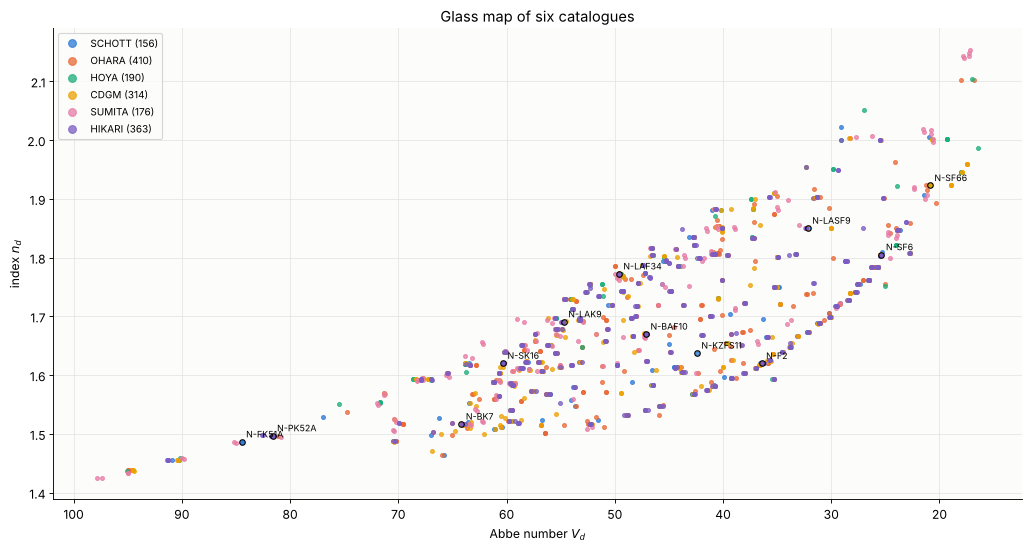

In [2]:
t = everything.table()
fig, ax = plt.subplots(figsize=(13, 7))
for v, col in VENDOR_COLORS.items():
    sel = np.array(t.vendors) == v
    ax.plot(t.Vd[sel], t.nd[sel], "o", ms=3.5, color=col, alpha=0.75, label=f"{v} ({sel.sum()})")
for name in ["N-FK51A", "N-PK52A", "N-BK7", "N-SK16", "N-LAK9", "N-BAF10", "N-F2", "N-SF6",
             "N-LASF9", "N-KZFS11", "N-SF66", "N-LAF34"]:
    g = gl.get(name, "schott")
    ax.plot(g.V_d, g.n_d, "ko", ms=5, mfc="none")
    ax.annotate(name, (g.V_d, g.n_d), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.invert_xaxis()
ax.set_xlabel("Abbe number $V_d$")
ax.set_ylabel("index $n_d$")
ax.set_title("Glass map of six catalogues")
ax.legend(fontsize=9, markerscale=2)
fig.tight_layout()

## 2. How good is a model glass?

The optimizer of notebook 58 varies glasses as points $(n_d, V_d)$ with
the Abbe model of `materials.abbe_dispersion()` (a Cauchy formula
$n = A + B/\lambda^2$ through $n_d$ and $n_F - n_C$). Within F to C it is
right by construction; outside it misses the curvature of the real
dispersion, most of all in the blue and for the flints, whose index rises
steeply towards their UV absorption.

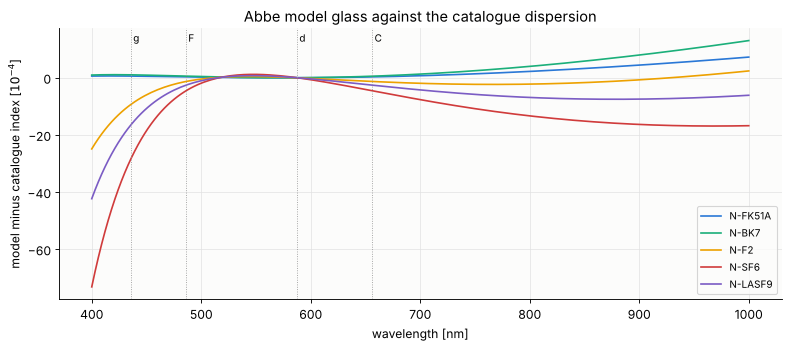

In [3]:
wl = np.linspace(400, 1000, 200)
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, col in [("N-FK51A", "#2a78d6"), ("N-BK7", "#1baf7a"), ("N-F2", "#eda100"),
                  ("N-SF6", "#d03b3b"), ("N-LASF9", "#7b5cc4")]:
    g = gl.get(name, "schott")
    ax.plot(wl, (abbe_dispersion(wl, g.n_d, g.V_d) - g.n(wl))*1e4, color=col, label=name)
for line in ("g", "F", "d", "C"):
    ax.axvline(gl.LINES[line], color="0.6", lw=0.8, ls=":")
    ax.annotate(line, (gl.LINES[line], 1), xycoords=("data", "axes fraction"), fontsize=9,
                xytext=(2, -12), textcoords="offset points")
ax.set_xlabel("wavelength [nm]")
ax.set_ylabel("model minus catalogue index [$10^{-4}$]")
ax.set_title("Abbe model glass against the catalogue dispersion")
ax.legend(fontsize=9)
fig.tight_layout()

Errors of $10^{-4}$ in the index already move the focus of a 100 mm lens
by tens of µm, so the model glass is a design tool, not a material: after
the glasses are chosen, the lens is corrected again with the real ones.

## 3. Partial dispersion and the normal line

The secondary spectrum of an achromat depends on how the dispersion is
distributed over the spectrum, measured by the relative partial
dispersion $P_{g,F} = (n_g - n_F)/(n_F - n_C)$. For most glasses it lies on
a straight line over $V_d$, the *normal line* through K7 and F2,
$P_{g,F} = 0.6438 - 0.001682\,V_d$. Two glasses on this line cannot bring
g to the focus of F and C. Glasses off the line, the fluor and phosphate
crowns above it and the short flints (KZFS) below it, can.

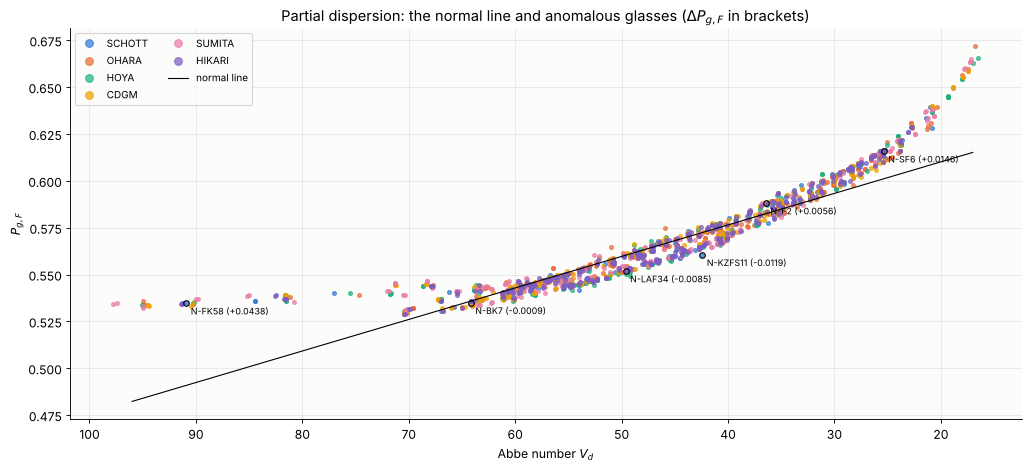

In [4]:
fig, ax = plt.subplots(figsize=(13, 6))
for v, col in VENDOR_COLORS.items():
    sel = np.array(t.vendors) == v
    ax.plot(t.Vd[sel], t.PgF[sel], "o", ms=3.5, color=col, alpha=0.7, label=v)
V = np.linspace(17, 96, 2)
ax.plot(V, gl.normal_line(V), "k-", lw=1, label="normal line")
for name in ["N-FK58", "N-BK7", "N-F2", "N-KZFS11", "N-LAF34", "N-SF6"]:
    g = gl.get(name, "schott")
    ax.plot(g.V_d, g.partial_dispersion(), "ko", ms=5, mfc="none")
    ax.annotate(f"{name} ({g.dPgF:+.4f})", (g.V_d, g.partial_dispersion()), xytext=(4, -10),
                textcoords="offset points", fontsize=8)
ax.invert_xaxis()
ax.set_xlabel("Abbe number $V_d$")
ax.set_ylabel("$P_{g,F}$")
ax.set_title("Partial dispersion: the normal line and anomalous glasses ($\\Delta P_{g,F}$ in brackets)")
ax.legend(fontsize=9, markerscale=2, ncol=2)
fig.tight_layout()

## 4. A doublet with a small secondary spectrum

For a thin achromat of focal length $f$ the g focus lies

$$
\Delta s_g = -f\,\frac{P_1 - P_2}{V_1 - V_2}
$$

away from the common focus of F and C, and the element powers are
$\varphi_1 = \varphi V_1/(V_1 - V_2)$, $\varphi_2 = -\varphi V_2/(V_1 - V_2)$
(`glasses.secondary_spectrum()`). A small secondary spectrum needs a
small $P_1 - P_2$, i.e. glasses on a line much flatter than the normal
line; but then often also a small $V_1 - V_2$, and strong lenses with
steep curves and large aberrations. Every crown/flint pair of SCHOTT's
standard and preferred glasses is one point in the trade-off.

3092 pairs; best N-FK58/N-LAF34: 42 um at f = 100 mm, crown power 2.20 phi; N-BK7/N-F2: 192 um, 2.31 phi


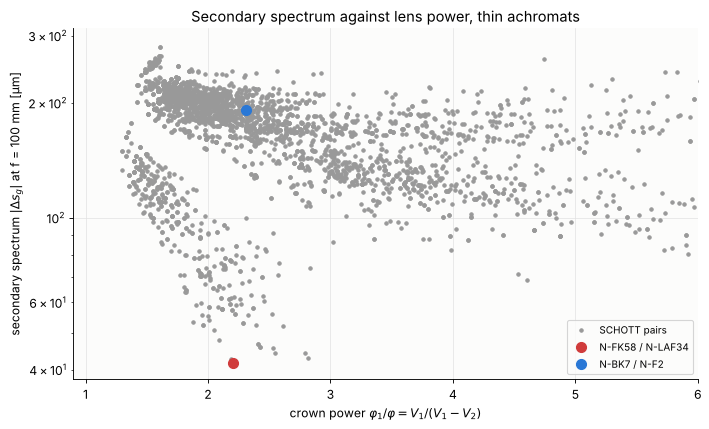

In [5]:
schott = gl.catalog("schott", status=("standard", "preferred"))
crowns = {k: g for k, g in schott.items() if g.V_d > 55}
flints = {k: g for k, g in schott.items() if g.V_d < 50}
pairs = []
for a, ga in crowns.items():
    for b, gb in flints.items():
        dV = ga.V_d - gb.V_d
        if dV > 8:
            pairs.append((a, b, abs(gl.secondary_spectrum(ga, gb, 100.0)), ga.V_d/dV))
pairs = sorted(pairs, key=lambda p: p[2])
best = pairs[0]
ref = [p for p in pairs if p[:2] == ("N-BK7", "N-F2")][0]
print(f"{len(pairs)} pairs; best {best[0]}/{best[1]}: {best[2]*1e3:.0f} um at f = 100 mm, "
      f"crown power {best[3]:.2f} phi; N-BK7/N-F2: {ref[2]*1e3:.0f} um, {ref[3]:.2f} phi")
fig, ax = plt.subplots(figsize=(9, 5.5))
ss, p1 = np.array([p[2] for p in pairs]), np.array([p[3] for p in pairs])
ax.semilogy(p1, ss*1e3, "o", ms=3, color="0.6", label="SCHOTT pairs")
for p, col in [(best, "#d03b3b"), (ref, "#2a78d6")]:
    ax.semilogy(p[3], p[2]*1e3, "o", ms=9, color=col, label=f"{p[0]} / {p[1]}")
ax.set_xlabel(r"crown power $\varphi_1/\varphi = V_1/(V_1 - V_2)$")
ax.set_ylabel(r"secondary spectrum $|\Delta s_g|$ at f = 100 mm [µm]")
ax.set_xlim(0.9, 6)
ax.set_title("Secondary spectrum against lens power, thin achromats")
ax.legend(fontsize=9)
fig.tight_layout()

The best pair, a fluor crown with a lanthanum flint, has a quarter of
the secondary spectrum of N-BK7/N-F2 at about the same powers. Both are
made into cemented doublets of f = 100 mm at F/5 with the real glasses:
focal length and F - C focus as constraints, spherical aberration and coma
from the Seidel sums as operands, the curvatures as variables (as in
notebook 58).

N-BK7 / N-F2: R = [48.0, -39.3, -335.8], W040 0.549, W131 -1.129 waves
N-FK58 / N-LAF34: R = [34.4, -46.6, -227.3], W040 0.681, W131 -3.322 waves


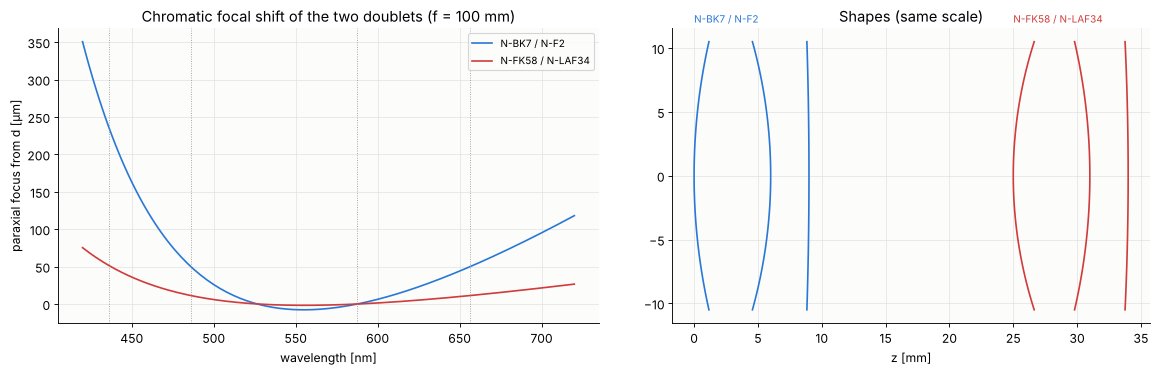

In [6]:
WL_d = gl.LINES["d"]*1e-6
WL_F, WL_C = gl.LINES["F"]*1e-6, gl.LINES["C"]*1e-6


def doublet(crown, flint, f=100.0, t1=6.0, t2=3.0, epd=20.0):
    (n1, V1), (n2, V2) = crown.model, flint.model
    p1, p2 = V1/(V1 - V2)/f, -V2/(V1 - V2)/f
    c1 = p1/(n1 - 1)/2
    c2 = -c1
    c3 = c2 - p2/(n2 - 1)
    S = [rt.Surface(1/c1, t1, material=crown), rt.Surface(1/c2, t2, material=flint),
         rt.Surface(1/c3, f, n_after=1.0)]
    s = rt.System(S, 0, WL_d, field_angle=np.deg2rad(1.0), entrance_pupil_radius=epd/2)

    return s.at_paraxial_focus()


def f_minus_c(s):
    return lo.focal_shift(WL_F, WL_C, tolerance=1.0)(s)[0]


cons = [lo.Constraint(lo.paraxial_value("efl"), 100.0, 100.0, 1e-3, "efl"),
        lo.Constraint(f_minus_c, 0.0, 0.0, 1e-4, "F - C")]
ops = [lo.seidel("W040", 0.0, 0.01), lo.seidel("W131", 0.0, 0.01)]
doublets = {}
for a, b, *_ in (ref, best):
    s = doublet(gl.get(a, "schott"), gl.get(b, "schott"))
    opt = lo.DampedLeastSquares(s, lo.curvatures(s), ops, cons, solves=[lo.solve_paraxial_focus()])
    r = opt.run()
    doublets[f"{a} / {b}"] = r.system
    sd = r.system.seidel()
    print(f"{a} / {b}: R = {[round(float(x.R), 1) for x in r.system.surfaces]}, "
          f"W040 {sd.W040:.3f}, W131 {sd.W131:.3f} waves")

wl = np.linspace(420, 720, 151)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for (name, s), col in zip(doublets.items(), ["#2a78d6", "#d03b3b"]):
    z0 = s.paraxial().image_distance
    z = [s.with_wavelength(w*1e-6).paraxial().image_distance - z0 for w in wl]
    axes[0].plot(wl, np.array(z)*1e3, color=col, label=name)
for line in ("g", "F", "d", "C"):
    axes[0].axvline(gl.LINES[line], color="0.6", lw=0.8, ls=":")
axes[0].set_xlabel("wavelength [nm]")
axes[0].set_ylabel("paraxial focus from d [µm]")
axes[0].set_title("Chromatic focal shift of the two doublets (f = 100 mm)")
axes[0].legend(fontsize=9)
for (name, s), col, off in zip(doublets.items(), ["#2a78d6", "#d03b3b"], [0, 25]):
    z = s.vertex_z
    y = np.linspace(-10.5, 10.5, 50)
    for i, surf in enumerate(s.surfaces):
        axes[1].plot(z[i] + surf.sag(y**2) + off, y, color=col)
    axes[1].text(off, 12, name, color=col, fontsize=9)
axes[1].set_aspect("equal")
axes[1].set_xlabel("z [mm]")
axes[1].set_title("Shapes (same scale)")
fig.tight_layout()

Both doublets bring F and C to one focus. In the ordinary achromat the g
focus lies about 0.18 mm behind it, as the thin lens formula says; in the
doublet of the anomalous pair only about 40 µm, and the whole curve from
420 to 720 nm is flatter. It is not yet an apochromat (three wavelengths
at one focus need a third glass, or an air spaced triplet), but most of
the secondary spectrum is gone. The price is a steeper front surface and
three times the coma of the ordinary achromat, which the cemented doublet
with these glasses cannot correct at the same time as the spherical
aberration: the glass choice for colour and for the monochromatic
aberrations compete.

## 5. From model glasses to real glasses

In notebook 58 the model glasses of an aplanatic cemented doublet
(efl, F - C, $W_{040}$ and $W_{131}$ zero) stopped at
$(1.531, 66.2)$ and $(1.625, 36.1)$. `snap_glasses()` with the whole
catalogue replaces them by the nearest real glasses with their own
dispersion formulas; the curvatures are then corrected again.

In [7]:
start = doublet(gl.get("N-BK7"), gl.get("N-F2"))
for i in (0, 1):
    start.surfaces[i].material = gl.get(("N-BK7", "N-F2")[i]).model  # model glasses
opt = lo.DampedLeastSquares(start, lo.curvatures(start) + lo.glass(0) + lo.glass(1), ops,
                            cons + [lo.glass_map_constraint(0), lo.glass_map_constraint(1)],
                            solves=[lo.solve_paraxial_focus()])
r = opt.run()
model = [opt.system.surfaces[i].material for i in (0, 1)]
print("model glasses:", [tuple(round(x, 4) for x in m) for m in model], f"merit {r.merit:.2g}")
for name, cat in [("SCHOTT", gl.catalog("schott")), ("all six vendors", everything)]:
    o = lo.DampedLeastSquares(r.system, lo.curvatures(r.system) + lo.glass(0) + lo.glass(1), ops,
                              cons, solves=[lo.solve_paraxial_focus()])
    chosen = o.snap_glasses(cat)
    rr = o.run()
    g = [o.system.surfaces[i].material for i in (0, 1)]
    sd = rr.system.seidel()
    print(f"{name:16s}: " + ", ".join(f"{x.name} ({x.vendor}, {x.n_d:.4f}/{x.V_d:.2f})" for x in g)
          + f"; after correction W040 {sd.W040:.3f}, W131 {sd.W131:.3f} waves")

model glasses: [(1.5307, 66.2647), (1.6256, 36.0342)] merit 5.3e-12
SCHOTT          : P-PK53 (SCHOTT, 1.5269/66.22), F2 (SCHOTT, 1.6200/36.37); after correction W040 0.203, W131 -0.063 waves


all six vendors : P-PK53 (SCHOTT, 1.5269/66.22), F5 (CDGM, 1.6244/35.94); after correction W040 0.085, W131 -0.020 waves


The nearest real crown, in SCHOTT's own catalogue, is P-PK53, a glass for
precision moulding, which lies almost on the model crown; with F2 as the
flint the corrected doublet keeps only a small part of the coma that
N-BK7/N-F2 leave (−1.13 waves, notebook 58). With all six catalogues the
flint becomes CDGM's F5, closer still to the model flint, and the
residuals shrink by another factor of two to three. A larger catalogue
makes the step from model glass to real glass smaller; in practice the
designer also weighs price, availability, transmission and the
chemical and thermal properties, which the catalogues of
refractiveindex.info partly carry but `pyoptics.glasses` does not use.

In [8]:
print(f"run time {time.time() - t_start:.0f} s")

run time 4 s


## References

- M. N. Polyanskiy, "Refractiveindex.info database of optical constants", Sci. Data 11, 94 (2024) (source of the catalogue data, CC0).
- SCHOTT AG, *Optical Glass - Data Sheets* and Technical Information TIE-29, "Refractive index and dispersion" (Sellmeier formula, partial dispersion, normal line).
- R. Kingslake and R. B. Johnson, *Lens Design Fundamentals*, 2nd ed., Academic Press (2010) (secondary spectrum, apochromats).
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008) (glass selection, secondary spectrum).
- R. D. Sigler, "Glass selection for airspaced apochromats using the Buchdahl dispersion equation", Appl. Opt. 25, 4311-4320 (1986).
- W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986).